In [159]:
import warnings
# turn off warnings
warnings.filterwarnings('ignore')

# data analysis
import datetime
import numpy as np
import pandas as pd

# preprocessing
from utils import DataCleanPipleLine
from sklearn.preprocessing import StandardScaler

# viz
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from utils import plotting as plot

# OS
import os
from dotenv import load_dotenv

load_dotenv()

# set theme for the book
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11})

title_params = {
    'fontsize' : 20,
    'fontweight' : 'bold',
    'color':'grey'
}

In [160]:
# Import the data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = cleaning_pipeline.RunPipeline()


****************************************************************************************************
DF Shape: (252893, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity
252892  2026-11-13 18:45:58             15.28  1001.99840  55.171876
252893  2026-11-13 18:46:58             15.27  1002.07080  55.148436
252894  2026-11-13 18:47:58             15.26  1002.07470  54.991210
252895  2026-11-13 18:48:59             15.27  1002.07080  54.625000
252896  2026-11-13 18:49:59             15.30  1002.08200  54.773436
252897  2026-11-13 18:50:59             15.38  1002.10456  54.939452
252898  2026-11-13 18:51:59             15.35  1002.06640  55.214844
252899  2026-11-13 18:52:59             15.40  1002.08152  55.398436
252900  2026-11-13 18:53:59             15.38  1002.10

In [161]:
# import data
file_location2 = os.getenv("F_LOC2")

# run data load
aq_cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location2)

# run pipeline
door_df = aq_cleaning_pipeline.RunPipeline()

****************************************************************************************************
DF Shape: (243724, 6)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity  eCo2  \
243723  2026-11-13 18:45:41             18.47  1003.70264  47.378908   423   
243724  2026-11-13 18:46:41             18.46  1003.71230  47.377930   421   
243725  2026-11-13 18:47:41             18.46  1003.76516  47.219728   437   
243726  2026-11-13 18:48:41             18.43  1003.74110  47.272460   415   
243727  2026-11-13 18:49:41             18.46  1003.73030  47.353516   436   
243728  2026-11-13 18:50:42             18.45  1003.77480  47.117188   429   
243729  2026-11-13 18:51:42             18.46  1003.83610  47.545900   434   
243730  2026-11-13 18:52:42             18.43  1003

In [162]:
# how much missing data do we have?
min_dt = window_df.index.min()
max_dt = window_df.index.max()

# create full date range df
dt_range = pd.date_range(
    start=min_dt,
    end=max_dt,
    freq='1min'
)

dt_range = pd.DataFrame(
    dt_range,
    columns=['date']
)
dt_range.head(5)

,date
0,2026-03-29 20:54:00+00:00
1,2026-03-29 20:55:00+00:00
2,2026-03-29 20:56:00+00:00
3,2026-03-29 20:57:00+00:00
4,2026-03-29 20:58:00+00:00


In [180]:
# merge the dfs together to show missing data
window_full_dt = pd.merge(
    left=dt_range,
    right=window_df,
    left_on='date',
    right_on=window_df.index,
    how='left'
)

window_full_dt.isna().sum()/len(window_df)

date                   0.000000
Temperature (oC)       0.303561
Pressure               0.303561
Humidity               0.303561
DateTime               0.303561
Date                   0.303561
UkDate                 0.303561
YearMonth              0.303561
EndOfWeek              0.303561
Time                   0.303561
Time_Numeric           0.303561
DailyAvgTemperature    0.303561
DailyAvgHumidity       0.303561
dtype: float64

In [181]:
# merge the dfs together to show missing data

door_full_dt = pd.merge(
    left=dt_range,
    right=door_df,
    left_on='date',
    right_on=door_df.index,
    how='left'
)

door_full_dt.isna().sum()/len(door_df)


date                   0.000000
Temperature (oC)       0.352633
Pressure               0.352633
Humidity               0.352633
eCo2                   0.352633
VOC                    0.352633
DateTime               0.352633
Date                   0.352633
UkDate                 0.352633
YearMonth              0.352633
EndOfWeek              0.352633
Time                   0.352633
Time_Numeric           0.352633
DailyAvgTemperature    0.352633
DailyAvgHumidity       0.352633
dtype: float64

##### Notes

We have a considerable amount of data missing from both dataframe (30% and 35%). The next step is to determine which method is a good approach to impute the data.

The options to explore are:

1. The mean.
2. Interpolation.

In [182]:
# explore the mean and it's impact on the data

missing_data_door_df_stats = door_df.describe()[['Humidity','Temperature (oC)']]
missing_data_window_df_stats= window_df.describe()[['Humidity','Temperature (oC)']]

# take the mean values
door_df_mean_hum, door_df_mean_tmp  = missing_data_door_df_stats.iloc[1].values
window_df_mean_hum, window_df_mean_tmp  = missing_data_window_df_stats.iloc[1].values

# fill in missing data with the mean
window_full_dt['Humidity_mean'] = window_full_dt['Humidity'].fillna(window_df_mean_hum)
window_full_dt['Temperature_mean'] = window_full_dt['Temperature (oC)'].fillna(window_df_mean_tmp)

# show how the data distributions have changed
print("Data with NaN")
print(missing_data_window_df_stats)
print(f"\n")
print("Data with NaN imputed")
print(window_full_dt[['Humidity_mean','Temperature_mean']].describe())

Data with NaN
            Humidity  Temperature (oC)
count  252878.000000     252878.000000
mean       52.748354         19.629698
min        26.669922         13.080000
25%        46.403320         17.170000
50%        53.474610         19.310000
75%        59.524412         21.690000
max        77.616210         29.740000
std         8.543223          3.019166


Data with NaN imputed
       Humidity_mean  Temperature_mean
count  329641.000000     329641.000000
mean       52.748338         19.629709
std         7.482663          2.644359
min        26.669922         13.080000
25%        48.784180         17.800000
50%        52.748354         19.629698
75%        57.668944         21.010000
max        77.616210         29.740000


##### Notes

It appears we have shrunk the distributions for both samples, as we have forced the data closer to the sample mean. The problem with this method is that we have artifically forced the distribution to be thinner (smaller standard deviation) and pull closer to the sample mean. The consequences are underestimated variance (overconfident intervals and tests) and weakened relationships between this feature and the others, since the imputed values carry no information about them.

If the number of missing values was smaller (<5% for example), I wouldn't be too concerned, but because we are dealing with a large amount of missing data, we are effectively altering our sample distribution in a negative way.

In [247]:
# lets try interpolation
window_full_dt.index = window_full_dt['date']
window_full_dt['Humidity_interpolate'] = window_full_dt['Humidity'].interpolate(method='pchip') # we want curives not straight lines
window_full_dt['Temperature_interpolate'] = window_full_dt['Temperature (oC)'].interpolate(method='pchip')

# show how the data distributions have changed
print("Data with NaN")
print(missing_data_window_df_stats)
print(f"\n")
print("Data with NaN imputed")
print(window_full_dt[['Humidity_interpolate','Temperature_interpolate']].describe())

Data with NaN
            Humidity  Temperature (oC)
count  252878.000000     252878.000000
mean       52.748354         19.629698
min        26.669922         13.080000
25%        46.403320         17.170000
50%        53.474610         19.310000
75%        59.524412         21.690000
max        77.616210         29.740000
std         8.543223          3.019166


Data with NaN imputed
       Humidity_interpolate  Temperature_interpolate
count         329641.000000            329641.000000
mean              53.455318                19.598485
std                8.552536                 2.978921
min               26.669922                13.080000
25%               46.962890                17.135714
50%               54.421876                19.230000
75%               60.563411                21.670000
max               77.616210                29.740000


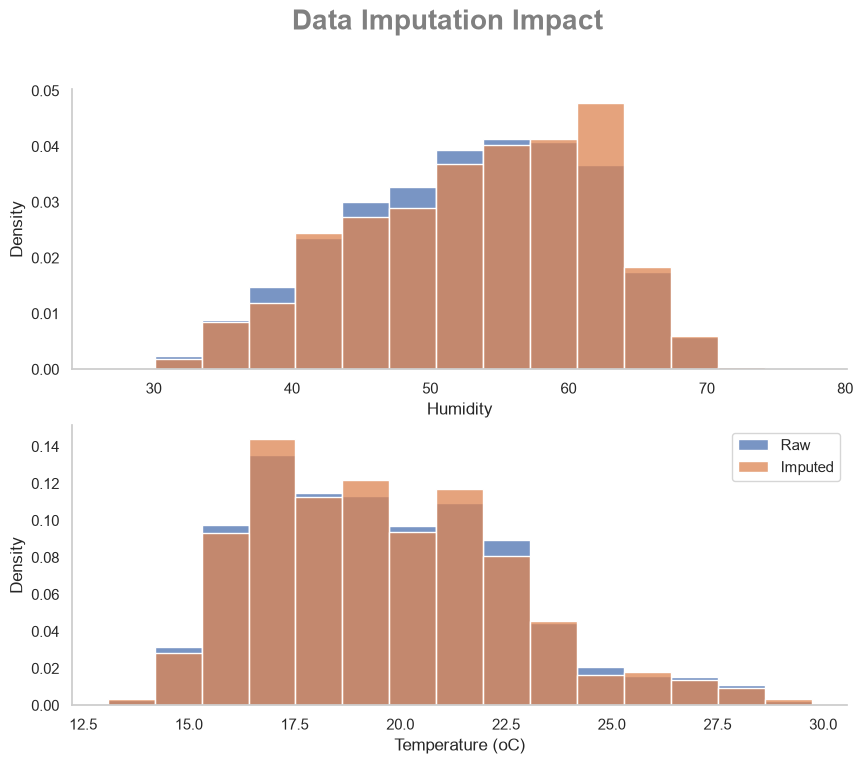

In [254]:
fig, axes = plt.subplots(2,1,figsize=(10,8))
bins=15
sns.histplot(
    data=window_full_dt,
    x='Humidity',
    stat='density', 
    common_norm=False, 
    bins=bins, 
    label='Raw',
    ax=axes[0]
)
sns.histplot(
    data=window_full_dt,
    x='Humidity_interpolate',
    stat='density', 
    common_norm=False, 
    bins=bins, 
    label='Imputed',
    ax=axes[0]
)
sns.histplot(
    data=window_full_dt,
    x='Temperature (oC)',
    stat='density', 
    common_norm=False, 
    bins=bins, 
    label='Raw',
    ax=axes[1]
)
sns.histplot(
    data=window_full_dt,
    x='Temperature_interpolate',
    stat='density', 
    common_norm=False, 
    bins=bins, 
    label='Imputed',
    ax=axes[1]
)


plt.legend()

# adjust visual
plot.plot_cleanup(axes, title="Data Imputation Impact")

##### Notes

This method of missing data imputation appears to have minimal effect of the distribution where there is a slight shift in mean and standard deviation, but it is not substantial!

**The shift:**

| Variable    | Statistic | Shift (abs) |
|-------------|-----------|-------------|
| Humidity    | Mean      | ±0.70       |
| Humidity    | Std       | ±0.01       |
| Temperature | Mean      | ±0.03       |
| Temperature | Std       | ±0.04       |

The distributions of both samples show little difference except between 60% and 70% in Humidity, but we can accept this as we will never get a perfect fit and there will be some differences. Therefore, we have established that interpolation preserved the distributions well and will be selected to impute the data.